# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Muh Fadhl Kautsar
- NIM   : 241011400088
- Kelas : 05TPLM001 Reg B

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [ ]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

RANDOM_STATE = 88

if not (os.path.exists('Ads_Data.csv') and os.path.exists('Email_Data.csv')):
    from google.colab import files
    print('Silakan upload Ads_Data.csv dan Email_Data.csv')
    files.upload()

print('RANDOM_STATE =', RANDOM_STATE)

RANDOM_STATE = 88


In [ ]:
def train_test_split(X, y, test_size=0.25, random_state=None):
    X = np.asarray(X)
    y = np.asarray(y)

    if not 0 < test_size < 1:
        raise ValueError("test_size must be between 0 and 1")

    n_total = len(X)
    n_test = int(round(n_total * test_size))

    if random_state is not None:
        rng = np.random.RandomState(random_state)
        indices = rng.permutation(n_total)
    else:
        indices = np.random.permutation(n_total)

    test_idx = indices[:n_test]
    train_idx = indices[n_test:]

    X_train = X[train_idx]
    X_test = X[test_idx]
    y_train = y[train_idx]
    y_test = y[test_idx]

    return X_train, X_test, y_train, y_test

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

Jumlah baris data : 40


,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Shape X : (40, 1)
Shape y : (40,)


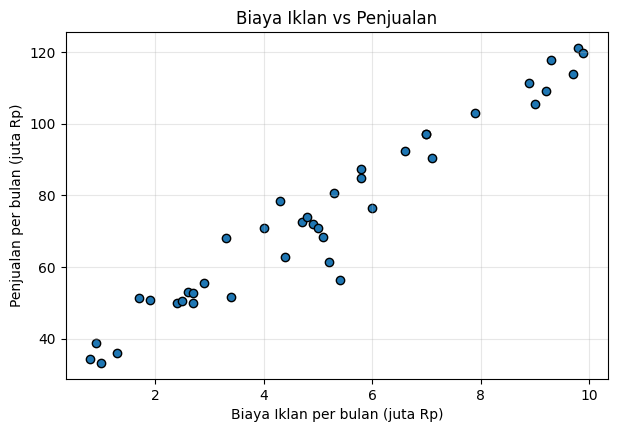

In [ ]:
df_ads = pd.read_csv('Ads_Data.csv')
print('Jumlah baris data :', len(df_ads))
display(df_ads.head())

X = df_ads[['BiayaIklan']].values     
y = df_ads['Penjualan'].values
print('Shape X :', X.shape)
print('Shape y :', y.shape)

plt.figure(figsize=(7, 4.5))
plt.scatter(X, y, color='tab:blue', edgecolor='k')
plt.title('Biaya Iklan vs Penjualan')
plt.xlabel('Biaya Iklan per bulan (juta Rp)')
plt.ylabel('Penjualan per bulan (juta Rp)')
plt.grid(alpha=0.3)
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print('X_train :', X_train.shape)
print('X_test  :', X_test.shape)
print('y_train :', y_train.shape)
print('y_test  :', y_test.shape)

X_train : (32, 1)
X_test  : (8, 1)
y_train : (32,)
y_test  : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [ ]:
class LinearRegression:
    def __init__(self):
        self.intercept_ = 0.0
        self.coefficients_ = None

    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        X_b = np.c_[np.ones(len(X)), X]                      
        beta = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y         

        self.intercept_ = beta[0]
        self.coefficients_ = beta[1:]
        return self

    def predict(self, X):
        X = np.array(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        return self.intercept_ + X @ self.coefficients_

lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)
b_ne = lin_reg.intercept_
m_ne = lin_reg.coefficients_[0]
print(f'Intercept (b)  : {b_ne:.4f}')
print(f'Koefisien (m)  : {m_ne:.4f}')
print(f'Persamaan      : y_hat = {b_ne:.4f} + {m_ne:.4f} * X')

Intercept (b)  : 28.9055
Koefisien (m)  : 9.0778
Persamaan      : y_hat = 28.9055 + 9.0778 * X


**Jawaban A3:**

Persamaan regresi yang diperoleh adalah $\hat{y} = 28{,}9055 + 9{,}0778X$. Koefisien $m = 9{,}0778$ berarti setiap kenaikan biaya iklan sebesar 1 juta Rp diikuti oleh kenaikan rata-rata penjualan sekitar 9,08 juta Rp. Ini adalah hubungan yang terlihat pada data (asosiasi), bukan bukti bahwa iklan satu-satunya penyebab naiknya penjualan. Intercept $b = 28{,}9055$ adalah perkiraan penjualan saat biaya iklan 0. Namun biaya iklan terkecil di data adalah 0,8 juta, sehingga angka ini hanya dipakai sebagai titik awal garis, bukan prediksi yang bisa dipercaya penuh.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [ ]:
def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - ss_res / ss_tot

y_pred_train = lin_reg.predict(X_train)
y_pred_test = lin_reg.predict(X_test)

hasil_eval = pd.DataFrame({
    'Training': [mae(y_train, y_pred_train), mse(y_train, y_pred_train),
                 rmse(y_train, y_pred_train), r2_score(y_train, y_pred_train)],
    'Testing':  [mae(y_test, y_pred_test), mse(y_test, y_pred_test),
                 rmse(y_test, y_pred_test), r2_score(y_test, y_pred_test)],
}, index=['MAE', 'MSE', 'RMSE', 'R2']).round(4)
display(hasil_eval)
print('Rata-rata Penjualan (seluruh data):', round(y.mean(), 2))

,Training,Testing
MAE,4.8456,3.0449
MSE,42.1471,12.9576
RMSE,6.4921,3.5997
R2,0.9296,0.9830


Rata-rata Penjualan (seluruh data): 74.27


**Jawaban A4:**

RMSE adalah rata-rata besar kesalahan prediksi dalam satuan asli (juta Rp). RMSE training 6,49 dan RMSE testing 3,60, artinya prediksi model meleset sekitar 3,6 sampai 6,5 juta Rp dari penjualan sebenarnya. Angka itu kecil dibanding rata-rata penjualan 74,27 juta Rp (sekitar 5% sampai 9%). $R^2$ training 0,9296 dan $R^2$ testing 0,9830, jadi garis regresi menjelaskan sekitar 93% sampai 98% variasi penjualan.

Model ini sudah baik untuk data ini, karena hubungan biaya iklan dan penjualan memang sangat linear (korelasi sekitar 0,97) dan tidak ada tanda overfitting: skor testing tidak lebih buruk dari skor training. Skor testing yang sedikit lebih bagus dari training tidak berarti model lebih pintar pada data baru. Data testing hanya 8 titik, sehingga hasilnya sangat dipengaruhi titik mana yang kebetulan masuk testing.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
<cell>:27: RuntimeWarning: overflow encountered in square
<cell>:24: RuntimeWarning: overflow encountered in matmul
<cell>:25: RuntimeWarning: invalid value encountered in subtract


,Metode,Learning rate,Intercept,Koefisien,MSE akhir
0,Normal Equation,-,28.905537,9.077803,42.147089
1,Gradient Descent,0.001,19.700108,10.552676,60.697454
2,Gradient Descent,0.02,28.905537,9.077803,42.147089
3,Gradient Descent,0.1,NaN,NaN,NaN


/usr/local/lib/python3.12/dist-packages/matplotlib/scale.py:270: RuntimeWarning: overflow encountered in power
  return np.power(self.base, values)


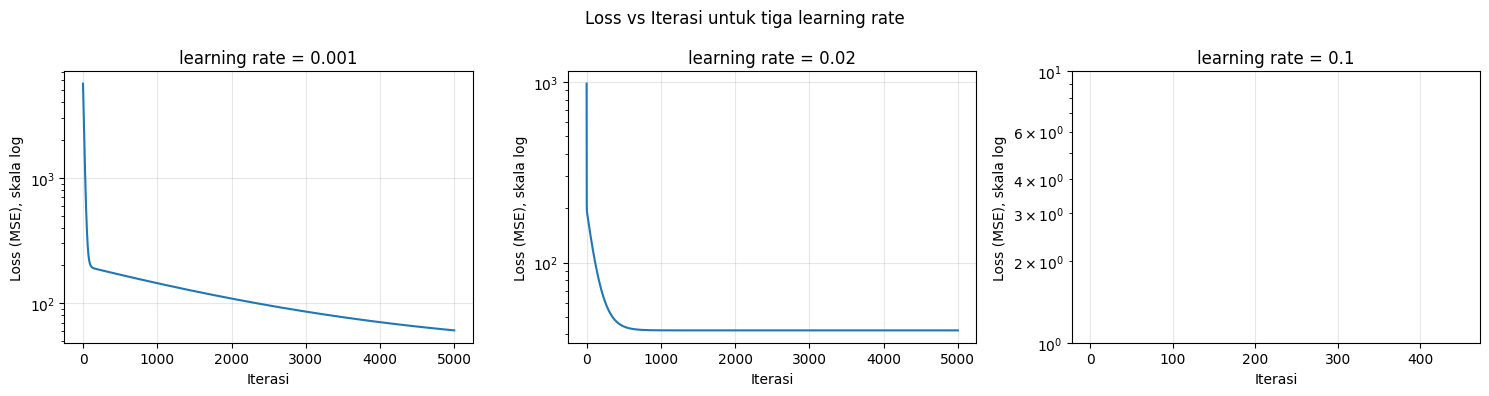

lr=0.001: loss iterasi 1 = 5635.61 | iterasi 1000 = 144.5 | iterasi 5000 = 60.7
lr=0.02: loss iterasi 1 = 979.21 | iterasi 1000 = 42.18 | iterasi 5000 = 42.15
lr=0.1: loss iterasi 1 = 27347.68 | iterasi 1000 = nan | iterasi 5000 = nan
lr=0.1: loss 5 iterasi pertama = [   27347.7   127373.8   595890.7  2790310.8 13068361.2]
lr=0.1: loss pertama kali tak hingga (inf/nan) pada iterasi ke- 451
lr=0.02: loss sudah dalam 0.01 dari nilai akhir sejak iterasi ke- 1129


In [ ]:
class LinearRegressionGD:
    def __init__(self, learning_rate=0.02, n_iterations=5000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coefficients_ = None
        self.loss_history_ = []
        self.beta_history_ = []

    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        X_b = np.c_[np.ones(len(X)), X]
        beta = np.zeros(X_b.shape[1])

        for _ in range(self.n_iterations):
            y_hat = X_b @ beta
            gradient = X_b.T @ (y_hat - y) / len(y)
            beta = beta - self.learning_rate * gradient

            loss = np.mean((y - X_b @ beta) ** 2)
            self.loss_history_.append(loss)
            self.beta_history_.append(beta.copy())

        self.intercept_ = beta[0]
        self.coefficients_ = beta[1:]
        return self

    def predict(self, X):
        X = np.array(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        return self.intercept_ + X @ self.coefficients_

learning_rates = [0.001, 0.02, 0.1]
models_gd = {}
baris = [{'Metode': 'Normal Equation', 'Learning rate': '-',
          'Intercept': b_ne, 'Koefisien': m_ne, 'MSE akhir': mse(y_train, y_pred_train)}]

for lr in learning_rates:
    gd = LinearRegressionGD(learning_rate=lr, n_iterations=5000)
    gd.fit(X_train, y_train)
    models_gd[lr] = gd
    baris.append({'Metode': 'Gradient Descent', 'Learning rate': lr,
                  'Intercept': gd.intercept_, 'Koefisien': gd.coefficients_[0],
                  'MSE akhir': gd.loss_history_[-1]})

display(pd.DataFrame(baris))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, lr in zip(axes, learning_rates):
    ax.semilogy(models_gd[lr].loss_history_)
    ax.set_title(f'learning rate = {lr}')
    ax.set_xlabel('Iterasi')
    ax.set_ylabel('Loss (MSE), skala log')
    ax.grid(alpha=0.3)
plt.suptitle('Loss vs Iterasi untuk tiga learning rate')
plt.tight_layout()
plt.show()

for lr in learning_rates:
    h = np.array(models_gd[lr].loss_history_)
    print(f'lr={lr}: loss iterasi 1 = {h[0]:.2f} | iterasi 1000 = {h[999]:.4g} | iterasi 5000 = {h[-1]:.4g}')
h = np.array(models_gd[0.1].loss_history_)
print('lr=0.1: loss 5 iterasi pertama =', np.round(h[:5], 1))
print('lr=0.1: loss pertama kali tak hingga (inf/nan) pada iterasi ke-', int(np.argmax(~np.isfinite(h))))
h2 = np.array(models_gd[0.02].loss_history_)
print('lr=0.02: loss sudah dalam 0.01 dari nilai akhir sejak iterasi ke-', int(np.argmax(h2 < h2[-1] + 0.01)))

**Jawaban A5:**

Catatan: `LinearRegressionGD` dari materi menghitung gradien sebagai $\frac{1}{n}X_b^T(\hat{y}-y)$ (tanpa faktor 2), jadi nilai learning rate di sini berlaku untuk rumus tersebut.

- **Learning rate 0,001 (terlalu lambat).** Setelah 5000 iterasi hasilnya masih jauh dari normal equation: intercept 19,70 dan koefisien 10,55, padahal seharusnya 28,91 dan 9,078. MSE-nya masih 60,70 (normal equation 42,15). Loss turun dari 144,5 pada iterasi ke-1000 menjadi 60,7 pada iterasi ke-5000 dan masih menurun, jadi langkahnya terlalu kecil dan butuh jauh lebih banyak iterasi.
- **Learning rate 0,02 (pas).** Intercept 28,9055 dan koefisien 9,0778 sama dengan normal equation, dan loss berhenti turun di 42,15. Loss sudah berada dalam 0,01 dari nilai akhir sejak sekitar iterasi ke-1129. Langkahnya cukup besar untuk cepat sampai, tetapi tidak sampai melewati titik minimum.
- **Learning rate 0,1 (divergen).** Loss justru naik di setiap iterasi (27.348, lalu 127.374, lalu 595.891, lalu 2,79 juta, dan seterusnya, sekitar 4 sampai 5 kali lipat tiap iterasi) sampai menjadi tak hingga sekitar iterasi ke-451, dan parameter akhirnya `nan`. Langkah yang terlalu besar membuat parameter melompati titik minimum ke sisi seberang dan mendarat lebih jauh dari sebelumnya, lalu terulang dengan jarak yang makin besar. Nilai `BiayaIklan` belum diskalakan (sampai 9,9), sehingga permukaan loss sangat curam dan batas learning rate yang aman menjadi kecil.

`RuntimeWarning: overflow` berarti nilai yang dihitung sudah melebihi batas angka `float64` (sekitar $1{,}8 \times 10^{308}$), sehingga menjadi `inf`. Operasi berikutnya pada `inf` menghasilkan `nan`. Ini bukan error kode, melainkan tanda bahwa training meledak karena learning rate terlalu besar.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

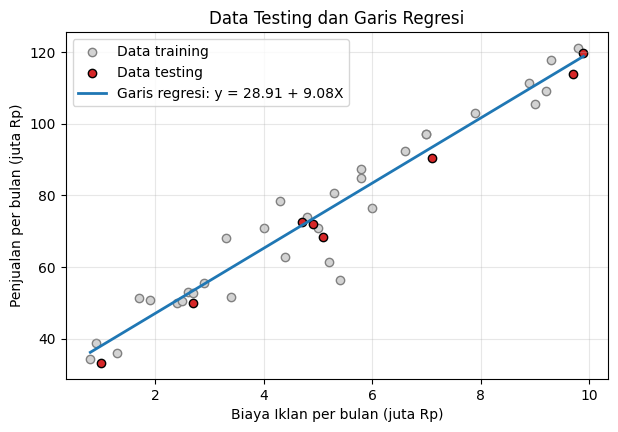

,BiayaIklan (juta Rp),Prediksi Penjualan (juta Rp),Di dalam rentang data?
0,4.5,69.76,Ya
1,7.0,92.45,Ya
2,12.0,137.84,Tidak (ekstrapolasi)


Rentang BiayaIklan pada data: 0.8 s.d. 9.9
Penjualan tertinggi pada data: 121.1


In [ ]:
garis_x = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
plt.figure(figsize=(7, 4.5))
plt.scatter(X_train, y_train, color='lightgray', edgecolor='gray', label='Data training')
plt.scatter(X_test, y_test, color='tab:red', edgecolor='k', label='Data testing')
plt.plot(garis_x, lin_reg.predict(garis_x), color='tab:blue', linewidth=2,
         label=f'Garis regresi: y = {b_ne:.2f} + {m_ne:.2f}X')
plt.title('Data Testing dan Garis Regresi')
plt.xlabel('Biaya Iklan per bulan (juta Rp)')
plt.ylabel('Penjualan per bulan (juta Rp)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

biaya_baru = np.array([[4.5], [7.0], [12.0]])
prediksi = lin_reg.predict(biaya_baru)
tabel_pred = pd.DataFrame({
    'BiayaIklan (juta Rp)': biaya_baru[:, 0],
    'Prediksi Penjualan (juta Rp)': prediksi.round(2),
    'Di dalam rentang data?': ['Ya' if X.min() <= v <= X.max() else 'Tidak (ekstrapolasi)' for v in biaya_baru[:, 0]],
})
display(tabel_pred)
print(f'Rentang BiayaIklan pada data: {X.min()} s.d. {X.max()}')
print(f'Penjualan tertinggi pada data: {y.max()}')

**Jawaban A6:**

Prediksi untuk biaya iklan 4,5 juta dan 7 juta (69,76 dan 92,45 juta Rp) berada di dalam rentang data (0,8 sampai 9,9 juta), jadi cukup bisa dipercaya karena model hanya melakukan interpolasi di daerah yang punya banyak data.

Prediksi untuk 12 juta (137,84 juta Rp) kurang bisa dipercaya karena itu ekstrapolasi, yaitu 2,1 juta di atas biaya iklan terbesar yang pernah ada di data. Model hanya tahu pola linear di rentang 0,8 sampai 9,9, dan tidak ada bukti bahwa pola yang sama berlaku di luar itu. Angka 137,84 juga lebih tinggi dari penjualan terbesar di data (121,1 juta Rp). Dalam praktik, biasanya ada efek jenuh (*diminishing returns*), yaitu tambahan iklan makin sedikit menaikkan penjualan karena pasar terbatas. Kalau itu terjadi, penjualan sebenarnya akan lebih rendah dari 137,84 juta. Hasil ini sebaiknya dianggap perkiraan kasar, bukan angka pasti.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

Jumlah baris data: 60


,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1


Jumlah Bukan Spam (0): 35
Jumlah Spam (1)      : 25
Shape X_email: (60, 2) | Shape y_email: (60,)


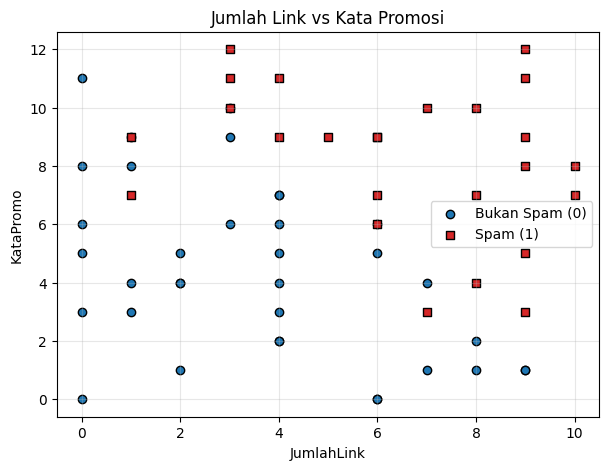

In [ ]:
df_email = pd.read_csv('Email_Data.csv')
print('Jumlah baris data:', len(df_email))
display(df_email.head())
jumlah_kelas = df_email['Spam'].value_counts().sort_index()
print('Jumlah Bukan Spam (0):', jumlah_kelas[0])
print('Jumlah Spam (1)      :', jumlah_kelas[1])

X_email = df_email[['JumlahLink', 'KataPromo']].values.astype(float)
y_email = df_email['Spam'].values
print('Shape X_email:', X_email.shape, '| Shape y_email:', y_email.shape)

plt.figure(figsize=(7, 5))
plt.scatter(X_email[y_email == 0, 0], X_email[y_email == 0, 1], color='tab:blue',
            edgecolor='k', label='Bukan Spam (0)')
plt.scatter(X_email[y_email == 1, 0], X_email[y_email == 1, 1], color='tab:red',
            edgecolor='k', marker='s', label='Spam (1)')
plt.title('Jumlah Link vs Kata Promosi')
plt.xlabel('JumlahLink')
plt.ylabel('KataPromo')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Shape train: (45, 2) | Shape test: (15, 2)
Intercept (b) : -13.4546
Koefisien m1  : 1.2446  (JumlahLink)
Koefisien m2  : 1.0172  (KataPromo)
P(Spam) = sigmoid(-13.4546 + 1.2446 * JumlahLink + 1.0172 * KataPromo)


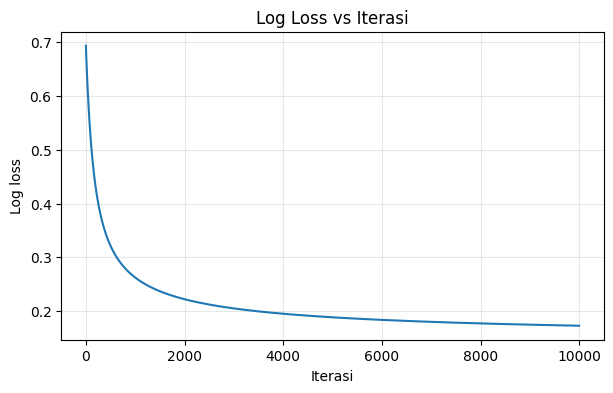

Log loss iterasi 1    : 0.6931
Log loss iterasi 1000 : 0.2625
Log loss iterasi 5000 : 0.1886
Log loss iterasi 9000 : 0.1749
Log loss iterasi 10000: 0.173


In [ ]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

class LogisticRegression:
    """Logistic regression dengan gradient descent; loss yang dipakai adalah log loss."""
    def __init__(self, learning_rate=0.1, n_iterations=1000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations

    def fit(self, X, y):
        m, n = X.shape
        self.intercept_ = 0.0
        self.coefficients_ = np.zeros(n)
        self.loss_history_ = []
        eps = 1e-15                                   # mencegah log(0)
        for _ in range(self.n_iterations):
            p = sigmoid(self.intercept_ + X @ self.coefficients_)
            self.loss_history_.append(-np.mean(y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps)))
            error = p - y                             # gradien log loss
            self.intercept_ -= self.learning_rate * np.mean(error)
            self.coefficients_ -= self.learning_rate * (X.T @ error) / m
        return self

    def predict_proba(self, X):
        return sigmoid(self.intercept_ + X @ self.coefficients_)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

Xe_train, Xe_test, ye_train, ye_test = train_test_split(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE)
print('Shape train:', Xe_train.shape, '| Shape test:', Xe_test.shape)

log_reg = LogisticRegression(learning_rate=0.1, n_iterations=10000).fit(Xe_train, ye_train)

b_log = log_reg.intercept_
m1, m2 = log_reg.coefficients_
print(f'Intercept (b) : {b_log:.4f}')
print(f'Koefisien m1  : {m1:.4f}  (JumlahLink)')
print(f'Koefisien m2  : {m2:.4f}  (KataPromo)')
print(f'P(Spam) = sigmoid({b_log:.4f} + {m1:.4f} * JumlahLink + {m2:.4f} * KataPromo)')

plt.figure(figsize=(7, 4))
plt.plot(log_reg.loss_history_)
plt.title('Log Loss vs Iterasi')
plt.xlabel('Iterasi')
plt.ylabel('Log loss')
plt.grid(alpha=0.3)
plt.show()

h = log_reg.loss_history_
print('Log loss iterasi 1    :', round(h[0], 4))
print('Log loss iterasi 1000 :', round(h[999], 4))
print('Log loss iterasi 5000 :', round(h[4999], 4))
print('Log loss iterasi 9000 :', round(h[8999], 4))
print('Log loss iterasi 10000:', round(h[-1], 4))

**Jawaban B2:**

Persamaan modelnya adalah $P(\text{Spam}) = \sigma(-13{,}4546 + 1{,}2446 \cdot \text{JumlahLink} + 1{,}0172 \cdot \text{KataPromo})$. Kedua koefisien bernilai positif, artinya makin banyak link dan makin banyak kata promosi, makin besar peluang email dianggap spam. Setiap tambahan satu link mengalikan *odds* spam sekitar 3,5 kali ($e^{1{,}2446}$), dan setiap tambahan satu kata promosi mengalikannya sekitar 2,8 kali ($e^{1{,}0172}$).

Loss sudah turun dan hampir stabil. Loss mulai dari 0,6931 (nilai $\ln 2$, karena parameter awal nol sehingga semua peluang 0,5), turun cepat menjadi 0,2625 pada iterasi ke-1000, lalu melandai ke 0,1886 pada iterasi ke-5000 dan 0,1730 di akhir. Dari iterasi 9000 ke 10000 loss hanya turun sekitar 0,002, jadi perubahannya sudah sangat kecil. Secara ketat loss masih turun sedikit, artinya model belum persis di titik optimum, tetapi 10.000 iterasi sudah cukup.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [ ]:
def accuracy_score(y_true, y_pred):
    return np.mean(y_true == y_pred)

def confusion_matrix(y_true, y_pred):
    """Mengembalikan [[TN, FP], [FN, TP]]."""
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tp = np.sum((y_true == 1) & (y_pred == 1))
    return np.array([[tn, fp], [fn, tp]])

def precision_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return tp / (tp + fp) if (tp + fp) > 0 else 0.0

def recall_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return tp / (tp + fn) if (tp + fn) > 0 else 0.0

def f1_score(y_true, y_pred):
    p, r = precision_score(y_true, y_pred), recall_score(y_true, y_pred)
    return 2 * p * r / (p + r) if (p + r) > 0 else 0.0

ye_pred = log_reg.predict(Xe_test)          
cm = confusion_matrix(ye_test, ye_pred)

print(f'Accuracy  : {accuracy_score(ye_test, ye_pred):.4f}')
print(f'Precision : {precision_score(ye_test, ye_pred):.4f}')
print(f'Recall    : {recall_score(ye_test, ye_pred):.4f}')
print(f'F1-score  : {f1_score(ye_test, ye_pred):.4f}')
print('\nConfusion matrix (data testing):')
display(pd.DataFrame(cm, index=['Aktual: Bukan Spam', 'Aktual: Spam'],
                     columns=['Prediksi: Bukan Spam', 'Prediksi: Spam']))
print('Akurasi data training:', round(accuracy_score(ye_train, log_reg.predict(Xe_train)), 4))

Accuracy  : 0.8667
Precision : 1.0000
Recall    : 0.7500
F1-score  : 0.8571

Confusion matrix (data testing):


,Prediksi: Bukan Spam,Prediksi: Spam
Aktual: Bukan Spam,7,0
Aktual: Spam,2,6


Akurasi data training: 0.9333


**Jawaban B3:**

Pada data testing (15 email) hasilnya: TN = 7, FP = 0, FN = 2, TP = 6. Dari angka itu, akurasi = 13/15 = 0,8667, precision = 1,00, recall = 0,75, dan F1 = 0,8571.

- **FP (*false positive*)**: email yang sebenarnya bukan spam, tetapi diprediksi spam. Email sah (misalnya info kuliah, tagihan, atau lamaran kerja) masuk folder spam.
- **FN (*false negative*)**: email yang sebenarnya spam, tetapi lolos ke inbox.

Menurut saya **FP lebih merugikan pengguna**. Email penting yang salah masuk folder spam bisa tidak terbaca sama sekali, sehingga pengguna kehilangan informasi atau kesempatan. Kalau spam lolos ke inbox, pengguna hanya terganggu sebentar dan bisa menghapusnya sendiri. Pada model ini FP = 0 (precision 1,00), tetapi 2 spam lolos (recall 0,75).

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Decision boundary: x2 = 13.2274 + (-1.2236) * x1


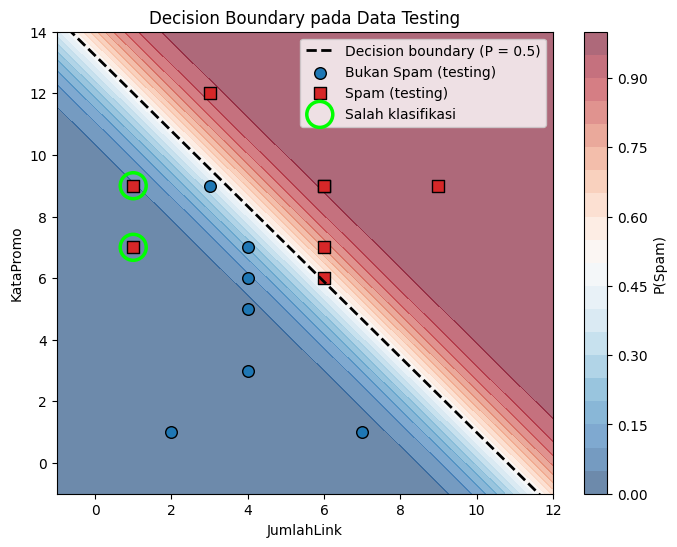

Data testing yang salah diklasifikasikan:


,JumlahLink,KataPromo,Label Asli,Prediksi,P(Spam)
0,1.0,7.0,1,0,0.0061
1,1.0,9.0,1,0,0.0450


Seluruh data testing beserta probabilitasnya:


,JumlahLink,KataPromo,Label Asli,P(Spam)
0,4.0,5.0,0,0.0326
1,7.0,1.0,0,0.0235
2,6.0,7.0,1,0.7565
3,3.0,12.0,1,0.9231
4,4.0,7.0,0,0.2049
5,6.0,9.0,1,0.9596
6,3.0,9.0,0,0.3621
7,1.0,7.0,1,0.0061
8,6.0,9.0,1,0.9596
9,4.0,3.0,0,0.0044


In [ ]:
intercept_garis = -b_log / m2
kemiringan_garis = -m1 / m2
print(f'Decision boundary: x2 = {intercept_garis:.4f} + ({kemiringan_garis:.4f}) * x1')

x1_grid, x2_grid = np.meshgrid(np.linspace(-1, 12, 300), np.linspace(-1, 14, 300))
grid = np.c_[x1_grid.ravel(), x2_grid.ravel()]
prob_grid = log_reg.predict_proba(grid).reshape(x1_grid.shape)

proba_test = log_reg.predict_proba(Xe_test)
salah = ye_pred != ye_test

fig, ax = plt.subplots(figsize=(8, 6))
cs = ax.contourf(x1_grid, x2_grid, prob_grid, levels=20, cmap='RdBu_r', alpha=0.6)
plt.colorbar(cs, label='P(Spam)')
xs = np.linspace(-1, 12, 100)
ax.plot(xs, intercept_garis + kemiringan_garis * xs, 'k--', linewidth=2, label='Decision boundary (P = 0.5)')
ax.scatter(Xe_test[ye_test == 0, 0], Xe_test[ye_test == 0, 1], color='tab:blue', edgecolor='k', s=70, label='Bukan Spam (testing)')
ax.scatter(Xe_test[ye_test == 1, 0], Xe_test[ye_test == 1, 1], color='tab:red', edgecolor='k', marker='s', s=70, label='Spam (testing)')
ax.scatter(Xe_test[salah, 0], Xe_test[salah, 1], facecolors='none', edgecolors='lime', s=350, linewidths=2.5, label='Salah klasifikasi')
ax.set_xlim(-1, 12); ax.set_ylim(-1, 14)
ax.set_title('Decision Boundary pada Data Testing')
ax.set_xlabel('JumlahLink'); ax.set_ylabel('KataPromo')
ax.legend(loc='upper right')
plt.show()

tabel_salah = pd.DataFrame({
    'JumlahLink': Xe_test[salah, 0], 'KataPromo': Xe_test[salah, 1],
    'Label Asli': ye_test[salah], 'Prediksi': ye_pred[salah],
    'P(Spam)': proba_test[salah].round(4)})
print('Data testing yang salah diklasifikasikan:')
display(tabel_salah)

print('Seluruh data testing beserta probabilitasnya:')
display(pd.DataFrame({'JumlahLink': Xe_test[:, 0], 'KataPromo': Xe_test[:, 1],
                      'Label Asli': ye_test, 'P(Spam)': proba_test.round(4)}))

**Jawaban B4:**

Decision boundary-nya adalah $x_2 = \dfrac{13{,}4546 - 1{,}2446\,x_1}{1{,}0172} \approx 13{,}23 - 1{,}22\,x_1$. Titik di sisi atas-kanan garis diprediksi spam, titik di sisi bawah-kiri diprediksi bukan spam.

Ada **2 data testing yang salah klasifikasi** (lingkaran hijau), keduanya spam yang diprediksi bukan spam (FN): email dengan `JumlahLink` = 1 dan `KataPromo` = 7 (P(Spam) = 0,006), serta `JumlahLink` = 1 dan `KataPromo` = 9 (P(Spam) = 0,045). Keduanya punya banyak kata promosi tetapi hanya satu link. Karena model menjumlahkan pengaruh link dan kata promosi secara linear, link yang sedikit menarik skor ke bawah dan banyaknya kata promosi tidak cukup mengimbanginya.

Beberapa titik juga berada dekat garis, misalnya spam (6, 6) yang benar tetapi hanya dengan P = 0,529, dan bukan spam (3, 9) dengan P = 0,362. Dua titik itu akan sangat dipengaruhi kalau threshold diubah (lihat B5).

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [ ]:
proba_test = log_reg.predict_proba(Xe_test)     
baris_thr = []
for thr in [0.3, 0.5, 0.7]:
    pred_thr = (proba_test >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(ye_test, pred_thr).ravel()
    baris_thr.append({'Threshold': thr, 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
                      'Accuracy': round(accuracy_score(ye_test, pred_thr), 4),
                      'Precision': round(precision_score(ye_test, pred_thr), 4),
                      'Recall': round(recall_score(ye_test, pred_thr), 4)})
display(pd.DataFrame(baris_thr))

,Threshold,TN,FP,FN,TP,Accuracy,Precision,Recall
0,0.3,6,1,2,6,0.8000,0.8571,0.750
1,0.5,7,0,2,6,0.8667,1.0000,0.750
2,0.7,7,0,3,5,0.8000,1.0000,0.625


**Jawaban B5:**

Menurunkan threshold membuat model lebih mudah menyebut email sebagai spam, sehingga biasanya *recall* naik dan *precision* turun. Menaikkan threshold membuat model lebih hati-hati, sehingga biasanya *precision* naik dan *recall* turun.

Pada data testing ini:
- **Threshold 0,3**: muncul 1 FP, yaitu email bukan spam dengan (3, 9) yang P = 0,362, sehingga precision turun menjadi 0,857. Recall tetap 0,75 karena dua spam yang lolos punya P di bawah 0,05, jauh di bawah 0,3. Jadi menurunkan threshold hanya menambah FP tanpa manfaat.
- **Threshold 0,5**: precision 1,00 dan recall 0,75.
- **Threshold 0,7**: recall turun ke 0,625 (FN menjadi 3) karena spam (6, 6) dengan P = 0,529 ikut lolos. Precision tetap 1,00.

Saya memilih **threshold 0,5**. Berdasarkan B3, FP lebih merugikan, jadi precision harus dijaga tinggi. Threshold 0,5 sudah memberi precision 1,00, sementara threshold 0,3 menurunkan precision tanpa menaikkan recall, dan 0,7 menurunkan recall tanpa menaikkan precision. Catatan: data testing hanya 15 email, jadi pilihan ini perlu diuji lagi pada data yang lebih banyak.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [ ]:
THRESHOLD = 0.5
email_baru = pd.DataFrame({'Email': ['E1', 'E2', 'E3', 'E4'],
                           'JumlahLink': [1, 5, 9, 2],
                           'KataPromo': [2, 6, 10, 11]})
proba_baru = log_reg.predict_proba(email_baru[['JumlahLink', 'KataPromo']].values.astype(float))
email_baru['P(Spam)'] = proba_baru.round(4)
email_baru['Prediksi'] = np.where(proba_baru >= THRESHOLD, 'Spam', 'Bukan Spam')
display(email_baru)

,Email,JumlahLink,KataPromo,P(Spam),Prediksi
0,E1,1,2,0.0000,Bukan Spam
1,E2,5,6,0.2445,Bukan Spam
2,E3,9,10,0.9996,Spam
3,E4,2,11,0.5557,Spam


**Jawaban B6:**

Dengan threshold 0,5, E1 (P = 0,0000) dan E2 (P = 0,2445) diprediksi **bukan spam**, sedangkan E3 (P = 0,9996) dan E4 (P = 0,5557) diprediksi **spam**. E3 sangat yakin spam karena link dan kata promosinya sama-sama tinggi. E4 hanya sedikit di atas threshold (link sedikit tetapi kata promosi banyak), sehingga keputusannya tipis dan bisa berubah kalau threshold dinaikkan ke 0,7.

---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:**

Logistic Regression termasuk klasifikasi karena keluaran akhirnya adalah kelas (Spam atau Bukan Spam), bukan angka kontinu. Kata "regression" ada karena model menghitung dulu kombinasi linear $z = b + m_1x_1 + m_2x_2$, seperti regresi linear. Fungsi sigmoid $\sigma(z) = \frac{1}{1+e^{-z}}$ lalu mengubah $z$ (yang bisa bernilai berapa saja) menjadi angka antara 0 dan 1 yang dibaca sebagai peluang kelas 1. Peluang itu dibandingkan dengan threshold (misalnya 0,5) untuk menentukan kelas. Contohnya email E3 mendapat P = 0,9996 sehingga diprediksi spam, dan E1 mendapat P = 0,000 sehingga bukan spam.

**Jawaban C2:**

Normal equation menghitung parameter langsung dengan rumus $\theta = (X^TX)^{-1}X^Ty$, sekali hitung dan tanpa learning rate. Gradient descent memperbarui parameter sedikit demi sedikit ke arah turunnya loss berulang kali, sehingga perlu memilih learning rate dan jumlah iterasi (seperti di A5, 0,001 terlalu lambat dan 0,1 divergen). Gradient descent lebih baik dipakai saat fitur atau datanya sangat banyak, karena invers matriks $X^TX$ menjadi mahal dan bisa bermasalah. Gradient descent juga dipakai untuk model yang tidak punya rumus langsung, seperti logistic regression. Untuk data kecil dengan satu fitur seperti tugas ini, hasil keduanya sama (b = 28,9055 dan m = 9,0778 pada learning rate 0,02).

**Jawaban C3:**

Model harus dievaluasi pada data testing karena data testing tidak dipakai saat training, sehingga nilainya menggambarkan kemampuan model pada data baru. Kalau dievaluasi pada data training, hasilnya terlalu optimis karena model sudah "melihat" data tersebut. Overfitting adalah kondisi saat model terlalu menyesuaikan diri dengan data training, termasuk noise-nya, sehingga skor training sangat bagus tetapi skor testing jauh lebih buruk. Pada tugas ini selisih akurasi training (0,9333) dan testing (0,8667) pada logistic regression tidak terlalu besar, jadi belum ada tanda overfitting yang serius.

**Jawaban C4:**

Linear Regression menghasilkan angka kontinu, jadi cara wajar mengukur kesalahannya adalah selisih kuadrat antara prediksi dan nilai asli (MSE). Loss ini berbentuk cekung (*convex*) untuk model linear dan memberi hukuman lebih besar pada selisih yang besar. Logistic Regression menghasilkan peluang antara 0 dan 1 untuk label 0 atau 1, sehingga lebih cocok memakai log loss yang berasal dari *maximum likelihood*. Log loss memberi hukuman sangat besar ketika model yakin tetapi salah (misalnya P = 0,01 padahal kelas aslinya 1). Jika MSE dipakai bersama sigmoid, loss tidak lagi cekung dan gradiennya bisa sangat kecil saat prediksi salah, sehingga training lebih sulit.

**Jawaban C5:**

Perbedaannya berasal dari `random_state`, yaitu dua digit terakhir NIM yang berbeda tiap mahasiswa. Nilai itu mengubah cara data diacak sebelum dibagi, sehingga isi data training dan testing berbeda. Model dilatih pada data yang berbeda sehingga koefisiennya berbeda, dan dievaluasi pada data testing yang berbeda sehingga metriknya juga berbeda. Efeknya besar di sini karena datanya sedikit (40 dan 60 baris), sehingga satu atau dua titik saja bisa mengubah akurasi atau $R^2$. Gradient descent di tugas ini selalu mulai dari parameter nol, jadi sumber perbedaannya hanya pembagian data.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [ ]:
from sklearn.linear_model import LinearRegression as SkLinearRegression
from sklearn.linear_model import LogisticRegression as SkLogisticRegression

sk_lin = SkLinearRegression().fit(X_train, y_train)
tabel_lin = pd.DataFrame({
    'Implementasi sendiri': [b_ne, m_ne, rmse(y_test, lin_reg.predict(X_test)), r2_score(y_test, lin_reg.predict(X_test))],
    'scikit-learn': [sk_lin.intercept_, sk_lin.coef_[0], rmse(y_test, sk_lin.predict(X_test)), r2_score(y_test, sk_lin.predict(X_test))],
}, index=['Intercept', 'Koefisien', 'RMSE test', 'R2 test']).round(6)
print('Perbandingan Linear Regression:')
display(tabel_lin)

sk_log_default = SkLogisticRegression(max_iter=100000).fit(Xe_train, ye_train)            # default: L2, C=1.0
sk_log_noreg = SkLogisticRegression(C=1e10, max_iter=100000).fit(Xe_train, ye_train)      # hampir tanpa regularisasi

def ringkas(nama, b, w, pred):
    return {'Model': nama, 'Intercept': b, 'm1 (JumlahLink)': w[0], 'm2 (KataPromo)': w[1],
            'Accuracy test': accuracy_score(ye_test, pred),
            'Precision test': precision_score(ye_test, pred), 'Recall test': recall_score(ye_test, pred)}

tabel_log = pd.DataFrame([
    ringkas('Implementasi sendiri (tanpa regularisasi)', log_reg.intercept_, log_reg.coefficients_, log_reg.predict(Xe_test)),
    ringkas('sklearn default (L2, C=1.0)', sk_log_default.intercept_[0], sk_log_default.coef_[0], sk_log_default.predict(Xe_test)),
    ringkas('sklearn C=1e10 (hampir tanpa regularisasi)', sk_log_noreg.intercept_[0], sk_log_noreg.coef_[0], sk_log_noreg.predict(Xe_test)),
]).round(4)
print('\nPerbandingan Logistic Regression:')
display(tabel_log)

Perbandingan Linear Regression:


,Implementasi sendiri,scikit-learn
Intercept,28.905537,28.905537
Koefisien,9.077803,9.077803
RMSE test,3.599671,3.599671
R2 test,0.983049,0.983049



Perbandingan Logistic Regression:


,Model,Intercept,m1 (JumlahLink),m2 (KataPromo),Accuracy test,Precision test,Recall test
0,Implementasi sendiri (tanpa regularisasi),-13.4546,1.2446,1.0172,0.8667,1.0,0.75
1,"sklearn default (L2, C=1.0)",-13.4325,1.2345,1.0138,0.8667,1.0,0.75
2,sklearn C=1e10 (hampir tanpa regularisasi),-24.6569,2.3590,1.7930,0.8667,1.0,0.75


**Jawaban Bonus:**

**Linear Regression:** intercept, koefisien, RMSE, dan $R^2$ implementasi sendiri sama dengan scikit-learn sampai 6 angka desimal. Keduanya memakai solusi kuadrat terkecil yang sama, jadi hasilnya memang harus sama.

**Logistic Regression:** hasilnya hampir sama dengan scikit-learn default, tetapi sangat berbeda dari scikit-learn tanpa regularisasi. Intinya:
- scikit-learn secara default memakai regularisasi L2 (`penalty='l2'`, `C=1.0`), yaitu menambah penalti pada besar koefisien. Koefisiennya (-13,43; 1,234; 1,014) hampir sama dengan hasil saya (-13,45; 1,245; 1,017).
- Implementasi saya tidak punya regularisasi. Karena itu saya bandingkan juga dengan `C=1e10` (penalti nyaris hilang). Koefisiennya jauh lebih besar (-24,66; 2,359; 1,793), artinya titik optimum tanpa penalti memang ada di nilai yang lebih besar.
- Gradient descent saya berhenti di iterasi ke-10.000 dengan loss yang masih turun sangat pelan, sehingga koefisiennya belum sampai ke optimum tanpa penalti dan masih lebih kecil. Kemiripan dengan `C=1.0` ini lebih karena penghentian lebih awal yang kebetulan bekerja seperti regularisasi, bukan karena kedua metode identik.
- Pada akurasi, precision, dan recall data testing ketiga model memberi hasil sama (akurasi 0,8667), karena perbedaan koefisien hanya menggeser kemiringan peluang, bukan keputusan pada 15 data testing ini.